# Qulacs batched execution

Compare sequential and parallel expectation-value calculations using the same circuit and parameter batch. The times depend on your computer; for small batches, worker startup can make parallel execution slower.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from threadpoolctl import threadpool_limits

from qc_executor import Executor, Parameters, QuantumCircuit, QuantumOperator

## Build a circuit and parameter batch

Each value in the batch produces one expectation value. Increase the number of values to explore larger workloads.

In [6]:
num_qubits = 16
num_workers = 4  # Set this to the number of CPUs available to your job.
parameter = Parameters("theta", 1)
circuit = QuantumCircuit(num_qubits)

for _ in range(4):
    for qubit in range(num_qubits):
        circuit.ry(qubit, parameter[0])
    for qubit in range(num_qubits - 1):
        circuit.cx(qubit, qubit + 1)

observable = QuantumOperator(["Z" * num_qubits], [1.0])
parameter_values = np.linspace(0.0, 1.0, 1024).reshape(-1, 1)
print("Parameter values:", len(parameter_values))

Parameter values: 1024


## Compare execution times

The parallel timing includes creating and starting the workers. Both runs use the same inputs and one native thread per worker.

In [7]:
sequential = Executor.create("qulacs", max_workers=1)
parallel = Executor.create("qulacs", max_workers=num_workers)

with threadpool_limits(limits=1):
    start = time.perf_counter()
    sequential_result = sequential.expectation_value(circuit, observable, theta=parameter_values)
    sequential_time = time.perf_counter() - start

    start = time.perf_counter()
    parallel_result = parallel.expectation_value(circuit, observable, theta=parameter_values)
    parallel_time = time.perf_counter() - start

np.testing.assert_allclose(sequential_result, parallel_result, atol=1e-10)
print(f"Sequential: {sequential_time:.2f} seconds")
print(f"Parallel ({num_workers} workers): {parallel_time:.2f} seconds")
print("Results match.")

Sequential: 10.49 seconds
Parallel (4 workers): 4.48 seconds
Results match.


## Compare the results

Lower bars mean shorter execution times. Parallel processing can be slower when the batch is too small to offset worker startup.

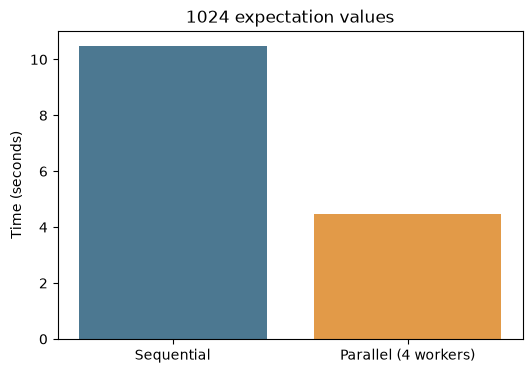

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    ["Sequential", f"Parallel ({num_workers} workers)"],
    [sequential_time, parallel_time],
    color=["#4c7891", "#e29a48"],
)
ax.set_ylabel("Time (seconds)")
ax.set_title(f"{len(parameter_values)} expectation values")
plt.show()